# 02 · A Huawei LUNA2000 battery

Same house, now with a 10 kWh / 5 kW battery behind a Huawei hybrid inverter.

The point of a *brand controller* is that the optimizer cannot drive the battery freely. The Huawei inverter is
either in **self-consumption** mode, where it follows its own greedy rule (PV surplus charges the battery, load
deficit is covered by the battery, each saturated by the power limit and by the SOC window), or it is **forced**
to charge or discharge at a setpoint. Switching the mode or changing a setpoint is a **command**, and we limit the
number of commands per horizon.

We compare three ways of running the same battery:

| label | controller | meaning |
|---|---|---|
| `inverter alone` | `HuaweiLuna2000Controller(mode="self_consumption")` | what you get without any optimizer |
| `optimized` | `HuaweiLuna2000Controller(max_commands=4)` | the optimizer schedules the modes and setpoints |
| `ideal` | `IdealController()` | perfect control at every step: a lower bound no real inverter reaches |

One subtlety makes the comparison fair. Left alone, an optimizer drains the battery before the end of the horizon
because stored energy is worth nothing to it, while the inverter alone ends wherever its rule leaves it. Fennec
therefore values the energy left in the battery at the end of the horizon (`Battery.terminal_value`, by default
the cheapest import price of the horizon) and adds `-price * (usable kWh at the end - usable kWh at the start)` to
the objective. The **objective** is then the bill net of that energy, and it is what the tables compare.

In [1]:
import sys
from pathlib import Path

# make the package importable without installing it (the notebooks live one level below the repo root)
src = Path().resolve().parent / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

import pandas as pd
pd.set_option("display.precision", 3)

In [2]:
from fennec import HuaweiLuna2000Controller, IdealController
from fennec.examples import baseline, huawei_battery
from fennec.utils import compare, plot_comparison, plot_dispatch

controllers = {
    "inverter alone": HuaweiLuna2000Controller(mode="self_consumption"),
    "optimized": HuaweiLuna2000Controller(max_commands=4, command_penalty=0.01),
    "ideal": IdealController(),
}

results = {"baseline": baseline().solve()}
for label, controller in controllers.items():
    results[label] = huawei_battery(controller=controller).solve(time_limit=120)
    print(f"{label:16s} {results[label]}  final SOC = {results[label].column('battery', 'soc_end')[-1]:.1f} %")

inverter alone   Results(status=optimal, objective=5.7740, assets=['grid', 'pv', 'house', 'battery'])  final SOC = 47.3 %


optimized        Results(status=optimal, objective=5.5649, assets=['grid', 'pv', 'house', 'battery'])  final SOC = 47.3 %


ideal            Results(status=optimal, objective=5.5349, assets=['grid', 'pv', 'house', 'battery'])  final SOC = 47.3 %


## How much is the battery worth, and how much does the brand cost?

`bill` is what the grid charges, `stored_value` the value of the energy gained (or lost, when negative) in the
battery over the horizon, and `objective` the bill net of it plus the command penalties. The saving column is
relative to the house without a battery. The gap between `optimized` and `ideal` is the price of the inverter's
restrictions; the gap between `inverter alone` and `optimized` is what the optimizer adds.

In [3]:
compare(results, reference="baseline")

,status,bill,stored_value,objective,import_kwh,export_kwh,solve_s,final_soc,commands,saving,saving_pct
baseline,optimal,7.766,0.000,7.766,56.76,16.06,0.01,NaN,NaN,0.000,0.0
inverter alone,optimal,5.745,-0.029,5.774,44.41,2.66,0.09,47.3,0.0,1.992,25.6
optimized,optimal,5.506,-0.029,5.565,44.60,2.66,9.21,47.3,3.0,2.201,28.3
ideal,optimal,5.506,-0.029,5.535,44.60,2.66,0.04,47.3,NaN,2.231,28.7


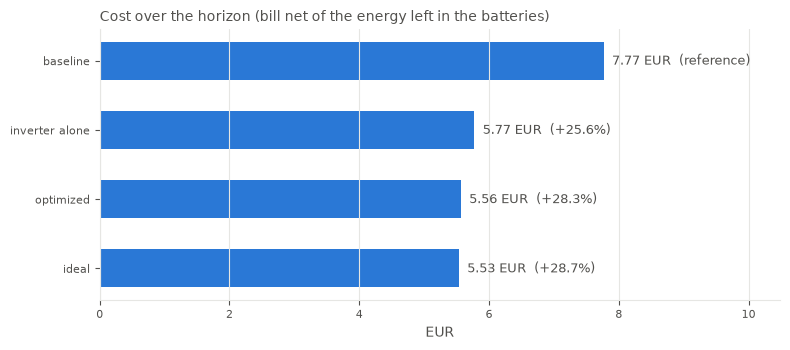

In [4]:
plot_comparison(results, reference="baseline");

## The inverter left alone

In self-consumption mode the battery charges with the midday surplus, is full by early afternoon (the rest of the
surplus is exported for nothing) and is empty before the evening peak ends. The shaded band marks the
self-consumption mode; it covers the whole horizon here.

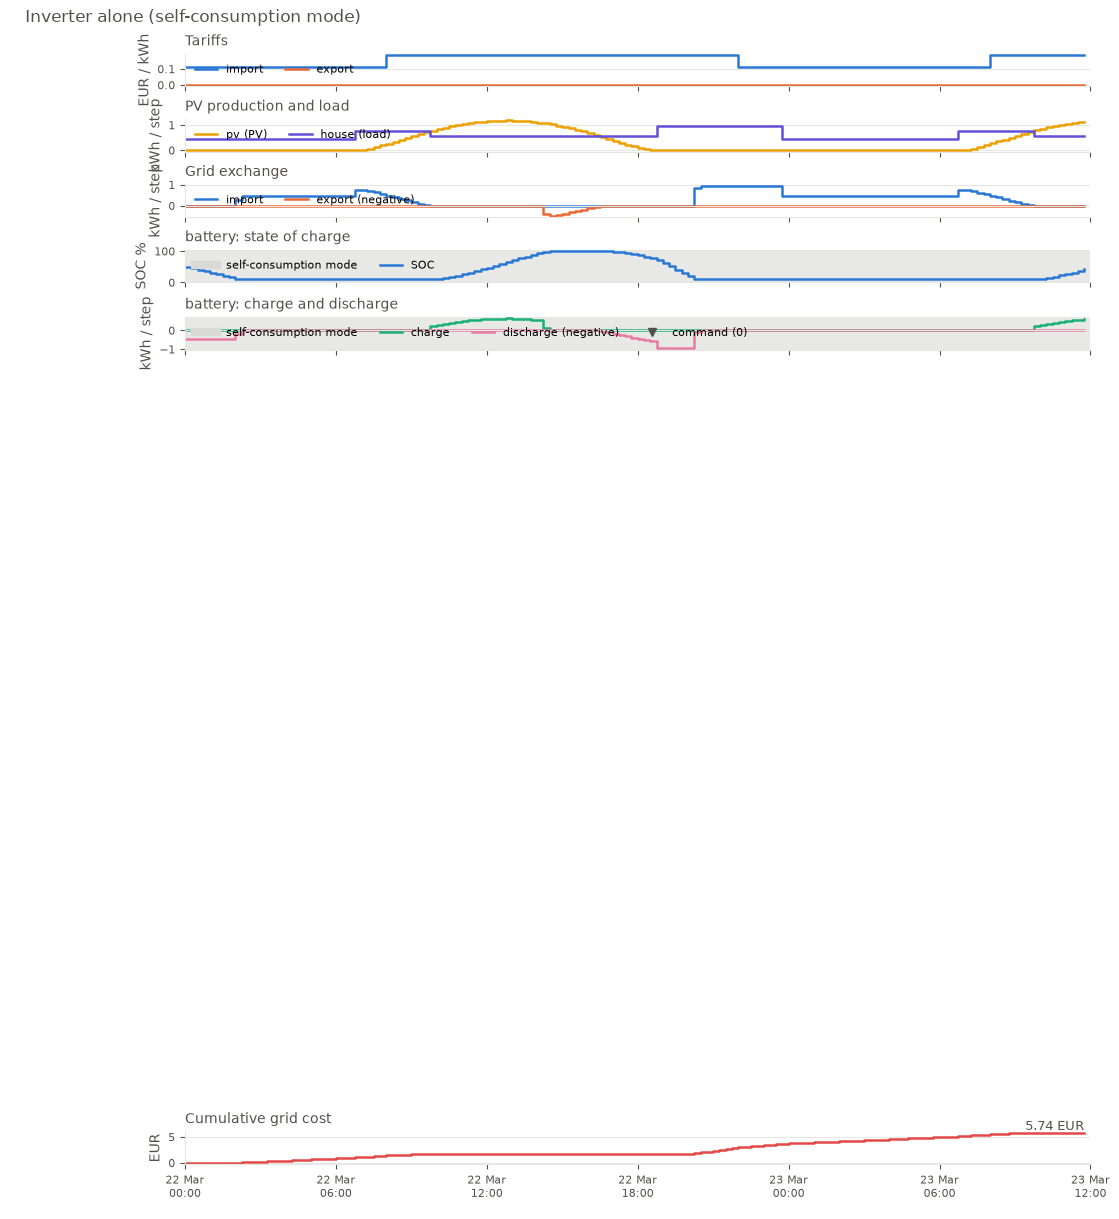

In [5]:
plot_dispatch(results["inverter alone"], title="Inverter alone (self-consumption mode)");

## The optimized schedule

With four commands the optimizer keeps the battery out of the way during the cheap night, hands the inverter back
to self-consumption for the day, and uses a forced charge from the grid in the second night to arrive at the
expensive morning with energy to spend. Command instants are marked with a tick.

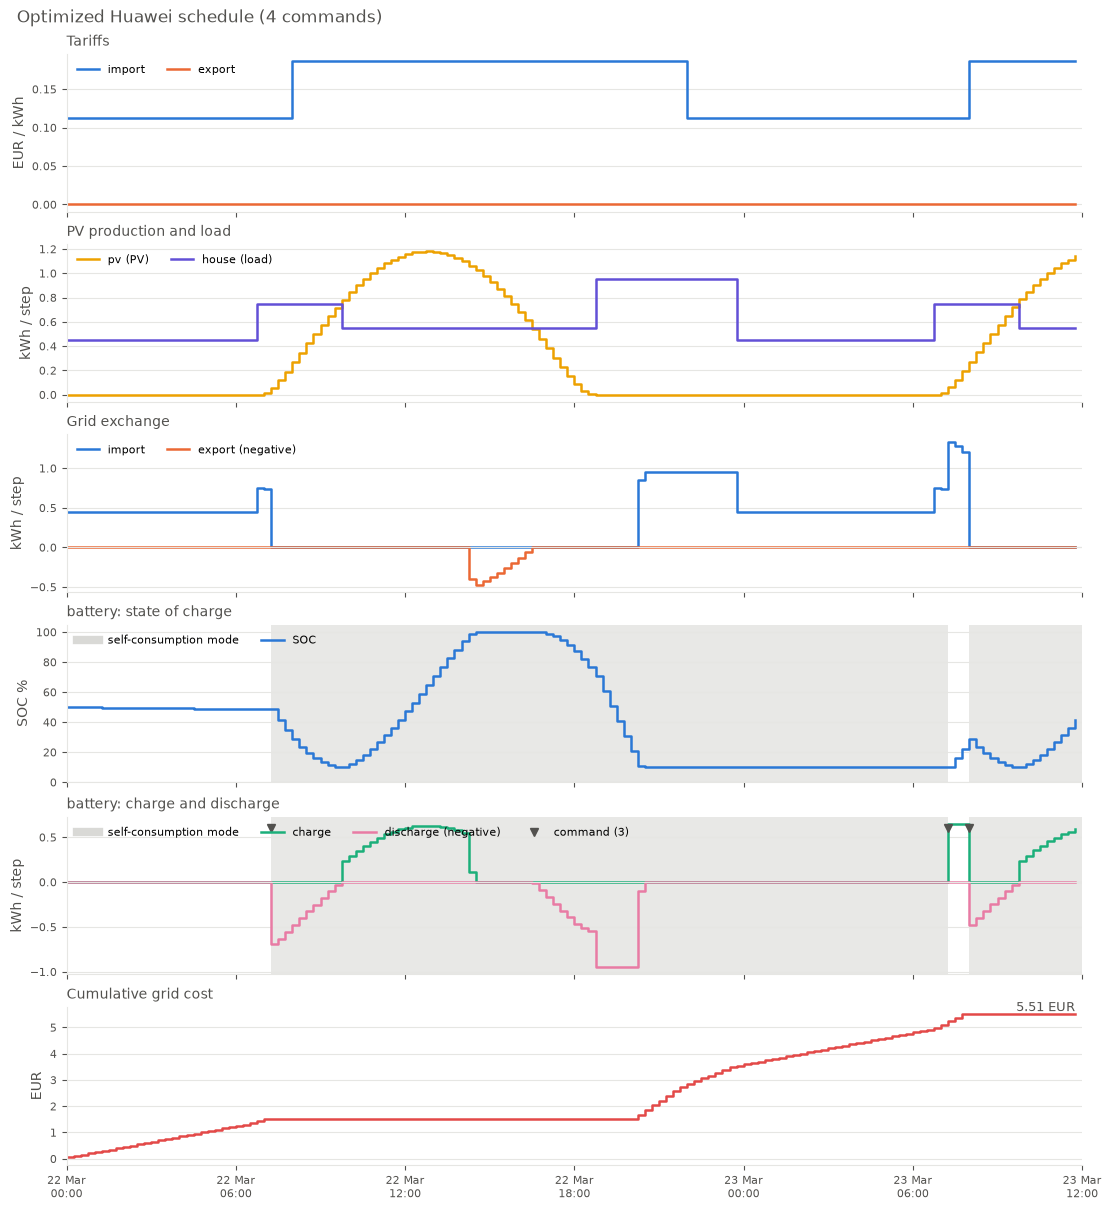

In [6]:
plot_dispatch(results["optimized"], title="Optimized Huawei schedule (4 commands)");

## How many commands are needed?

Each command is a Modbus / FusionSolar write. Here the inverter starts in self-consumption mode
(`initial_mode`), so leaving that mode already costs one command, and zero commands is the inverter alone. The
marginal value of each further command drops quickly.

In [7]:
sweep = {}
for n in (0, 1, 2, 4, 8):
    controller = HuaweiLuna2000Controller(max_commands=n, command_penalty=0.01, initial_mode="self_consumption")
    sweep[f"{n} commands"] = huawei_battery(controller=controller).solve(time_limit=120)
compare({"baseline": results["baseline"], **sweep, "ideal": results["ideal"]}, reference="baseline")

,status,bill,stored_value,objective,import_kwh,export_kwh,solve_s,final_soc,commands,saving,saving_pct
baseline,optimal,7.766,0.000,7.766,56.76,16.06,0.01,NaN,NaN,0.000,0.0
0 commands,optimal,5.745,-0.029,5.774,44.41,2.66,0.09,47.3,0.0,1.992,25.6
1 commands,optimal,5.745,-0.029,5.774,44.41,2.66,5.76,47.3,0.0,1.992,25.6
2 commands,optimal,5.614,-0.029,5.663,44.41,2.66,12.25,47.3,2.0,2.103,27.1
4 commands,optimal,5.506,-0.029,5.575,44.60,2.66,11.13,47.3,4.0,2.191,28.2
8 commands,optimal,5.506,-0.029,5.575,44.60,2.66,8.16,47.3,4.0,2.191,28.2
ideal,optimal,5.506,-0.029,5.535,44.60,2.66,0.04,47.3,NaN,2.231,28.7
